# HSA_Cam_B_013.py
This file uses the LHHW_Model of kinetics and KLD to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_004.py is the model. This uses homoscedastic noise and exponential priors.

Analysis from the related python script.

### Plan:
* load the data
* generate the plots
* check the reduction in KLD
* check the reduction in HDI
* check the parameter uncertainties
* check the exploration pattern

### Results:
* Leave out the first 4 experiments completely

In [40]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [41]:
from HSA_Cam_B_013 import (
    SIDX,
    TRUE_PARAMS,
    bmodel,
    _kinetics_model,
    input_p,
    observe_at_proposal,
    post_model_over_T,
    true_model_over_T,
    plot_post_model_at_proposal,
    kl_divergence_between_models,
)

In [42]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [43]:
exp_run_name = "uttermost-colonnade"
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [44]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [45]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [46]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [47]:
# just for the prior, generate the base model
T, p, c2h, f, c2i, _ = observe_at_proposal(proposals)
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)
with model:
    prior = pm.sample_prior_predictive(draws=1000)

display(prior)
idatas.insert(0, prior)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\jax\linker.py:32: UserWarning:

The RandomType SharedVariables [RNG(<Generator(PCG64) at 0x224947C0200>), RNG(<Generator(PCG64) at 0x224947C2F80>), RNG(<Generator(PCG64) at 0x224947C3060>), RNG(<Generator(PCG64) at 0x224947C3140>), RNG(<Generator(PCG64) at 0x224947C0AC0>), RNG(<Generator(PCG64) at 0x224947C0F20>), RNG(<Generator(PCG64) at 0x224947C0C80>), RNG(<Generator(PCG64) at 0x224947C2180>), RNG(<Generator(PCG64) at 0x224947C3CA0>), RNG(<Generator(PCG64) at 0x224947C3D80>)] will not be used in the compiled JAX graph. Instead a copy will be used.

Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]


Inference data with groups:
	> prior
	> prior_predictive
	> observed_data

### Display the results:

In [53]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    test_res = post_model_over_T(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = true_model_over_T(
        proposal=proposals[j],
    )
    plot_post_model_at_proposal(
        proposal=proposals[j],
        test_res=test_res,
        true_res=true_res,
        Ts=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(ylim=(0, 0.0006))
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=5), IntSlider(value=0, description='Pro…

### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_4936\2035428282.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



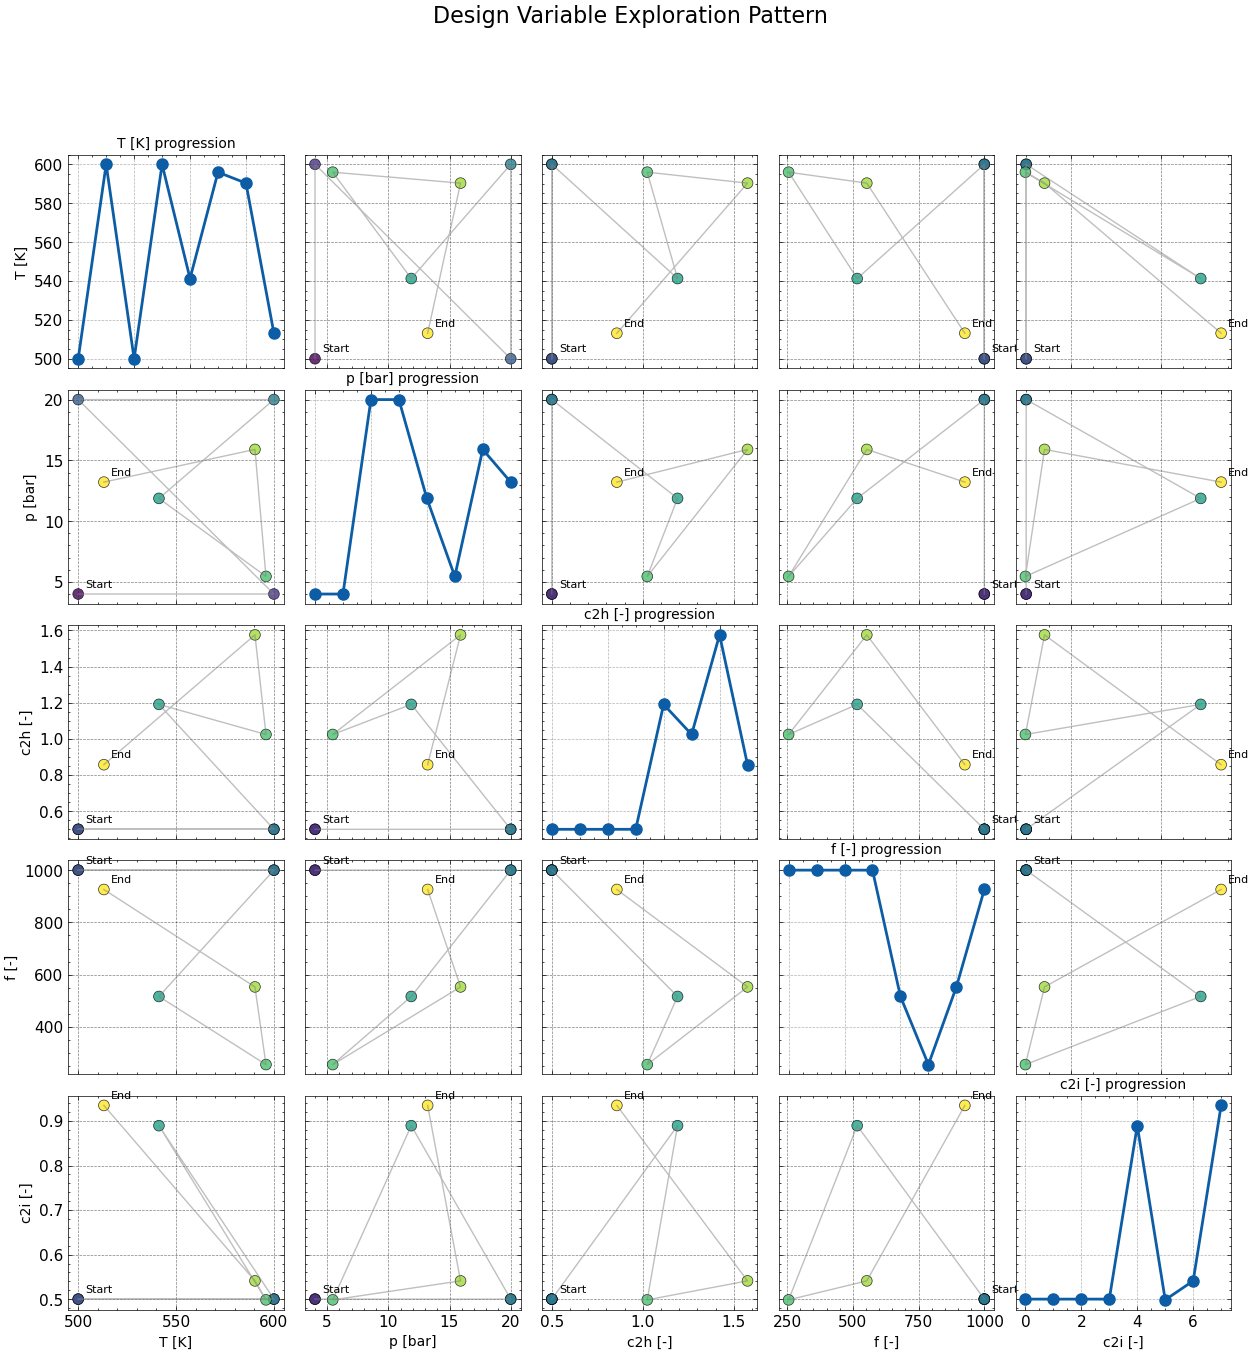

In [54]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = ["T [K]", "p [bar]", "c2h [-]", "f [-]", "c2i [-]"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [82]:
import xarray

info_gains = []
for i in range(1, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i - 1],
        key_new="posterior",
        key_old="posterior" if i > 1 else "prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "y_hat",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[1.79766746 1.6471047  0.09861761 0.06217042 0.48978155 0.13934732
 0.3395755  0.14155323 0.87945354]
5.595271331837038
[1.55172468 2.25810578 0.03843757 0.04530411 0.1019295  0.18393134
 0.10026208 0.08733455 0.21757397]
4.584603589832133
[0.02865005 0.19715004 0.01912114 0.00510566 0.72072216 0.00687147
 0.40830666 0.01260984 0.14656133]
1.5450983498420636
[0.81526245 0.05844881 0.01773096 0.02229073 0.08313325 0.00231836
 0.59500437 0.00298618 0.083635  ]
1.6808101201993098
[ 1.32541245e+00  3.09997650e-01 -3.22979475e-03 -2.17487133e-04
  8.79488579e-02  6.45147694e-03  1.11036833e+00  8.33187316e-03
 -1.01896871e-02]
2.8348736765653397


In [83]:
expected_KLDs = [trial["expected"]["KLD"] for trial in exp_summary["trials"]]

Text(0, 0.5, 'info gain as per KL divergence')

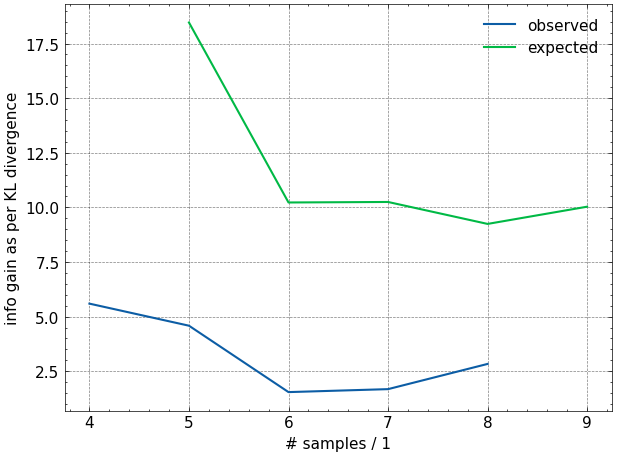

In [84]:
plt.plot(np.arange(len(kldses)) + 4, kldses, label="observed")
plt.plot(np.arange(len(kldses)) + 5, expected_KLDs, label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [ ]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['dH_h2', 'dH_mix', 'k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'A_mix', 'sigma_r', 'y_hat']


interactive(children=(Dropdown(description='Parameter:', index=2, options=('dH_h2', 'dH_mix', 'k0', 'Ea_k', 'A…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=4), Output()), _dom_classes=('widget-in…

In [87]:
az.summary(idatas[-1], round_to=5)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
dH_h2,-10460.66642,4927.77276,-19639.24707,-1170.39952,51.89478,38.96079,9021.74292,10145.57011,1.00083
dH_mix,-11204.53345,5052.18896,-21061.81915,-2113.72519,56.41390,40.75542,8043.32087,10011.55604,1.00013
k0,0.00030,0.00006,0.00018,0.00042,0.00000,0.00000,4891.43054,5853.26219,1.00121
Ea_k,79620.88162,10383.10728,60568.97143,98626.95508,149.30871,176.74630,5145.77054,5830.11294,1.00086
A_oh,0.99018,0.98123,0.00013,2.78511,0.00866,0.01181,7449.73442,5448.83477,1.00092
dH_oh,9905.42869,10014.70175,1.01933,27523.55471,83.58532,133.49804,8106.07156,5622.91984,1.00025
A_h2,0.39337,0.07979,0.24677,0.54692,0.00099,0.00109,6731.86542,6878.93804,1.00158
A_mix,0.86716,0.14853,0.59976,1.15088,0.00207,0.00192,5185.35094,6346.42834,1.00058
sigma_r,0.00001,0.00000,0.00000,0.00002,0.00000,0.00000,4650.77777,4066.88748,1.00160
"y_hat[0, 0]",0.00001,0.00000,0.00000,0.00001,0.00000,0.00000,5867.24552,5596.77381,1.00058
